# Task 2 - Decision Tree (DT)

This notebook implements the Decision Tree part of Task 2: multiclass classification of the nine power-quality disturbances (PQDs).

The workflow is deliberately leakage-safe:

1. combine the SNR datasets and keep the SNR as metadata;
2. make one stratified train/validation split;
3. select the classifier configuration with stratified 5-fold cross-validation on the training partition;
4. fit the selected model on all training data and evaluate once on validation data;
5. report overall and per-SNR accuracy, precision, recall, and F1 score.

The held-out validation set is not used for model selection.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 12
TEST_SIZE = 0.20
CV_SPLITS = 5

SNR_LEVELS = ["SNR_noiseless", "SNR_50db", "SNR_40db", "SNR_30db", "SNR_20db"]
CLASS_NAMES = [
    "Normal",
    "Sag",
    "Swell",
    "Interruption",
    "Harmonics",
    "Sag_harmonics",
    "Swell_harmonics",
    "Transient",
    "Flicker",
]
NORMAL_LABEL = "Normal"
normal_precision_scorer = make_scorer(
    precision_score,
    labels=[NORMAL_LABEL],
    average="macro",
    zero_division=0,
)

# The Task 1 positional convention maps raw columns to the F1-F8 names below.
FEATURE_COLUMNS = ["F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8"]
RAW_TO_FEATURE = {
    "avg abs": "F2",
    "sd": "F3",
    "max": "F4",
    "min": "F5",
    "no. pks": "F6",
    "sd fma": "F7",
    "sd fma 3": "F1",
    "no. pt near 0": "F8",
}

# Make the notebook independent of the directory from which Jupyter was started.
current = Path.cwd().resolve()
DATA_ROOT = next(
    (path / "Code" / "01 Task" for path in [current, *current.parents]
     if (path / "Code" / "01 Task").is_dir()),
    None,
)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find Code/01 Task. Run this notebook inside the project "
        "repository or update DATA_ROOT."
    )
print(f"Using data from: {DATA_ROOT}")


Using data from: /Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/05 Project/EE4C12---Machine-Learning-Project/Code/01 Task


## 1. Load and label all SNR datasets

Each CSV contains one row per signal sample. The filename is the PQD class label;
the first CSV column is an index and is intentionally ignored. SNR is retained
in a separate column so that robustness can be inspected after the final
evaluation.


In [2]:
def load_feature_data(data_root):
    frames = []
    for snr in SNR_LEVELS:
        snr_dir = data_root / snr
        if not snr_dir.is_dir():
            raise FileNotFoundError(f"Missing SNR directory: {snr_dir}")
        for csv_path in sorted(snr_dir.glob("*.csv")):
            label = csv_path.stem
            if label not in CLASS_NAMES:
                raise ValueError(f"Unexpected class file: {csv_path.name}")
            frame = pd.read_csv(csv_path).rename(columns=RAW_TO_FEATURE)
            missing = set(FEATURE_COLUMNS) - set(frame.columns)
            if missing:
                raise ValueError(f"{csv_path} is missing features: {sorted(missing)}")
            frame = frame[FEATURE_COLUMNS].copy()
            frame["label"] = label
            frame["snr"] = snr.removeprefix("SNR_")
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)


dataset = load_feature_data(DATA_ROOT)
X = dataset[FEATURE_COLUMNS]
y = dataset["label"]
print(f"Loaded {len(dataset):,} samples and {X.shape[1]} features.")
display(dataset.groupby(["snr", "label"]).size().unstack(fill_value=0))


Loaded 6,705 samples and 8 features.


label,Flicker,Harmonics,Interruption,Normal,Sag,Sag_harmonics,Swell,Swell_harmonics,Transient
snr,,,,,,,,,
20db,149,149,149,149,149,149,149,149,149
30db,149,149,149,149,149,149,149,149,149
40db,149,149,149,149,149,149,149,149,149
50db,149,149,149,149,149,149,149,149,149
noiseless,149,149,149,149,149,149,149,149,149


## 2. Create a stratified train/validation split

Stratification preserves the class proportions in both partitions. The pipeline
Decision Trees do not require feature scaling because their splits depend on
feature order rather than feature magnitude. The tree is fitted separately
inside every cross-validation fold and later on the training partition only.


In [3]:
X_train, X_valid, y_train, y_valid, snr_train, snr_valid = train_test_split(
    X,
    y,
    dataset["snr"],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Training samples: {len(X_train):,}")
print(f"Validation samples: {len(X_valid):,}")


Training samples: 5,364
Validation samples: 1,341


## 3. Cross-validate the Decision Tree on the training partition

The candidate tree depths, split criteria, and minimum leaf sizes are evaluated with stratified 5-fold cross-validation. Macro-F1 is used for selection so every PQD contributes equally.


In [4]:
candidates = [
    {"max_depth": None, "min_samples_leaf": 1, "criterion": "gini"},
    {"max_depth": 8, "min_samples_leaf": 1, "criterion": "gini"},
    {"max_depth": 12, "min_samples_leaf": 2, "criterion": "entropy"},
    {"max_depth": 16, "min_samples_leaf": 2, "criterion": "log_loss"},
]
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for candidate in candidates:
    pipeline = Pipeline(
        [("tree", DecisionTreeClassifier(
            **candidate, random_state=RANDOM_STATE
        ))]
    )
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro",
            "normal_precision": normal_precision_scorer,
        },
        n_jobs=-1,
    )
    cv_rows.append({
        **candidate,
        "accuracy_mean": scores["test_accuracy"].mean(),
        "precision_macro_mean": scores["test_precision_macro"].mean(),
        "recall_macro_mean": scores["test_recall_macro"].mean(),
        "f1_macro_mean": scores["test_f1_macro"].mean(),
        "f1_macro_std": scores["test_f1_macro"].std(),
        "normal_precision_mean": scores["test_normal_precision"].mean(),
        "normal_precision_std": scores["test_normal_precision"].std(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    ["normal_precision_mean", "f1_macro_mean"], ascending=False
)
display(cv_results.reset_index(drop=True))
best_params = cv_results.iloc[0][["max_depth", "min_samples_leaf", "criterion"]].to_dict()
print("Selected configuration:", best_params)


,max_depth,min_samples_leaf,criterion,accuracy_mean,precision_macro_mean,recall_macro_mean,f1_macro_mean,f1_macro_std,normal_precision_mean,normal_precision_std
0,NaN,1,gini,0.976137,0.976269,0.976141,0.976140,0.005109,0.929878,0.013668
1,16.0,2,log_loss,0.977441,0.977670,0.977446,0.977465,0.004667,0.927678,0.016641
2,12.0,2,entropy,0.978560,0.978877,0.978568,0.978602,0.004134,0.925151,0.012892
3,8.0,1,gini,0.975018,0.975623,0.975019,0.975043,0.004251,0.899361,0.015029


Selected configuration: {'max_depth': nan, 'min_samples_leaf': 1, 'criterion': 'gini'}


## 4. Fit the selected Decision Tree and evaluate on held-out validation data

The following metrics are the final validation results. Macro-averaging gives
each class equal weight; weighted-F1 additionally reflects the class support.
The confusion matrix shows which PQDs are confused with one another.


,Metric,Value
0,Accuracy,0.972409
1,Macro precision,0.972613
2,Macro recall,0.972409
3,Macro F1,0.972486
4,Weighted F1,0.972486


,precision,recall,f1-score,support
Normal,0.888889,0.912752,0.900662,149.0
Sag,0.986577,0.986577,0.986577,149.0
Swell,1.000000,0.993289,0.996633,149.0
Interruption,0.986577,0.986577,0.986577,149.0
Harmonics,1.000000,1.000000,1.000000,149.0
Sag_harmonics,1.000000,1.000000,1.000000,149.0
Swell_harmonics,1.000000,1.000000,1.000000,149.0
Transient,0.938776,0.926174,0.932432,149.0
Flicker,0.952703,0.946309,0.949495,149.0


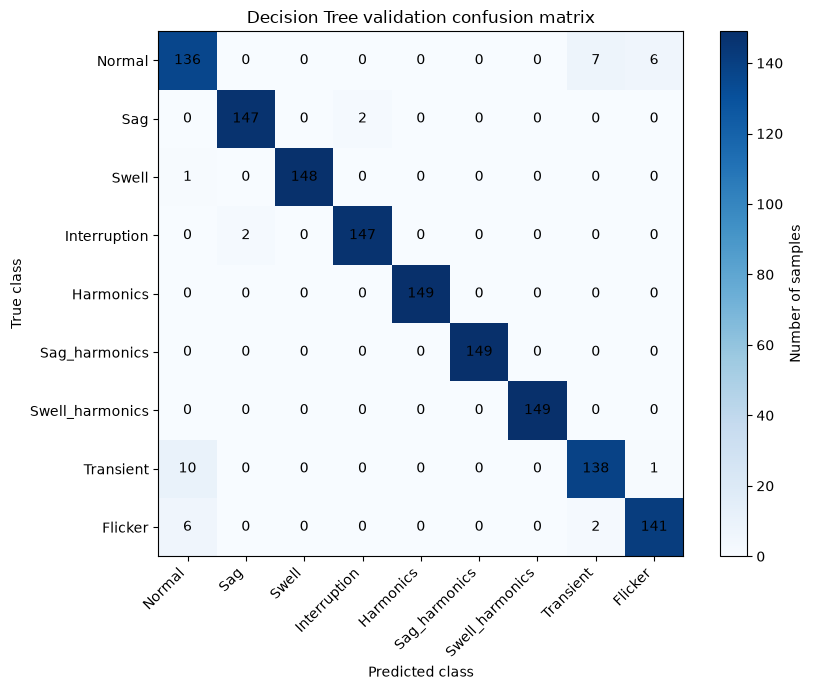

In [5]:

final_model = Pipeline(
    [("tree", DecisionTreeClassifier(
        max_depth=None if pd.isna(best_params["max_depth"]) else int(best_params["max_depth"]),
        min_samples_leaf=int(best_params["min_samples_leaf"]),
        criterion=best_params["criterion"],
        random_state=RANDOM_STATE,
    ))]
)
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_valid)

overall_metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Macro precision", "Macro recall", "Macro F1", "Weighted F1"],
        "Value": [
            accuracy_score(y_valid, y_pred),
            precision_score(y_valid, y_pred, average="macro", zero_division=0),
            recall_score(y_valid, y_pred, average="macro", zero_division=0),
            f1_score(y_valid, y_pred, average="macro", zero_division=0),
            f1_score(y_valid, y_pred, average="weighted", zero_division=0),
        ],
    }
)
display(overall_metrics)

report = pd.DataFrame(
    classification_report(
        y_valid, y_pred, labels=CLASS_NAMES, output_dict=True, zero_division=0
    )
).T
display(report.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]])

fig, ax = plt.subplots(figsize=(9, 7))
confusion = confusion_matrix(y_valid, y_pred, labels=CLASS_NAMES)
image = ax.imshow(confusion, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of samples")
for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        ax.text(column, row, confusion[row, column], ha="center", va="center")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Decision Tree validation confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Evaluate robustness at each SNR level

This is a diagnostic breakdown of the same held-out validation predictions.
It does not refit the model for each SNR, so the numbers describe how one MLP
trained on the complete range of noise conditions behaves as contamination
increases.


,SNR,Samples,Accuracy,Macro precision,Macro recall,Macro F1
0,40db,281,0.996441,0.996416,0.997076,0.996697
1,30db,280,0.992857,0.993056,0.992696,0.992815
2,20db,255,0.878431,0.875102,0.873251,0.874054
3,50db,262,0.996183,0.995726,0.996633,0.996112
4,noiseless,263,0.992395,0.993464,0.992518,0.992827


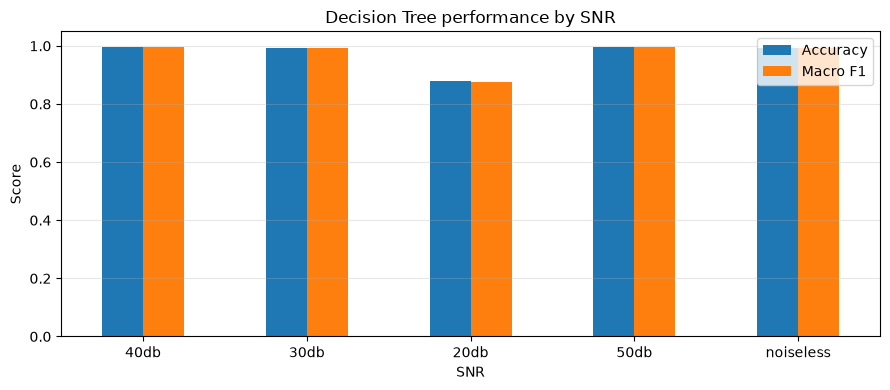

In [6]:
validation_results = dataset.loc[X_valid.index, ["snr"]].copy()
validation_results["label"] = y_valid
validation_results["prediction"] = y_pred

snr_rows = []
for snr, group in validation_results.groupby("snr", sort=False):
    snr_rows.append(
        {
            "SNR": snr,
            "Samples": len(group),
            "Accuracy": accuracy_score(group["label"], group["prediction"]),
            "Macro precision": precision_score(
                group["label"], group["prediction"], labels=CLASS_NAMES,
                average="macro", zero_division=0
            ),
            "Macro recall": recall_score(
                group["label"], group["prediction"], labels=CLASS_NAMES,
                average="macro", zero_division=0
            ),
            "Macro F1": f1_score(
                group["label"], group["prediction"], labels=CLASS_NAMES,
                average="macro", zero_division=0
            ),
        }
    )
snr_results = pd.DataFrame(snr_rows)
display(snr_results)

ax = snr_results.set_index("SNR")[["Accuracy", "Macro F1"]].plot(
    kind="bar", ylim=(0, 1.05), figsize=(9, 4), rot=0
)
ax.set_ylabel("Score")
ax.set_title("Decision Tree performance by SNR")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Interpretation

Use the cross-validation table, validation metrics, class report, confusion matrix, and SNR table to discuss Decision Tree effectiveness. For the full Task 2 submission, compare this model with the Random Forest and MLP using the same split and metric definitions.
